# Volatility-adjusted momentum on a halal universe

This backtests a monthly-rebalanced, long-only strategy over the tickers in `equities-list.csv`
(rows with `Asset Type == Stock`; the ETFs in that file are excluded since the strategy ranks
individual names against each other). The CSV labels these as halal *candidates* only —
independently verify current Shariah compliance before investing.

**Strategy specification**

Instead of ranking stocks by raw trailing return, divide return by realized volatility:

$$ \text{MomentumScore}_i = \frac{R_{12m,\,i}}{\sigma_{60d,\,i}} $$

where $R_{12m}$ is the trailing 12-month return and $\sigma_{60d}$ is annualized realized
volatility over the trailing 60 trading days (daily-return standard deviation, annualized by
$\sqrt{252}$). Every month:

1. Compute each eligible stock's 12-month return and 60-day annualized volatility.
2. Score it as return divided by volatility.
3. Rank the universe by score and buy the top 20%, equal-weighted.
4. Rebalance monthly — full reset, no hold-band.

The point of dividing by volatility: a stock that grinds up steadily can outscore one that
posted a bigger headline return by being far more volatile getting there.

| Stock | 12M return | Volatility | Score |
|---|---|---|---|
| A | 40% | 30% | 1.33 |
| B | 35% | 15% | 2.33 |
| C | 50% | 60% | 0.83 |

B wins here despite the lowest raw return, because it earned that return with a third of C's
volatility. This is particularly relevant for this universe: names like NVDA, AMD, MU, and PLTR
can post similar headline returns while carrying dramatically different volatility profiles, and
raw-return ranking (as in the other momentum notebooks) can't tell those apart.

Daily bars are reused from the other momentum notebooks' shared cache (`data/daily/`) — the
acquisition cell below is identical and simply fetches anything that isn't already cached.

## Before running

1. Install dependencies: `pip install ib-insync pandas numpy matplotlib pandas-datareader`
2. Run IBKR Trader Workstation or IB Gateway, enable API connections, and use a market-data-enabled
   account.
3. Set the host, port, and client ID below. Typical paper ports are 7497 for TWS and 4002 for
   Gateway; live ports are commonly 7496 and 4001.
4. Run the acquisition cell once. It shares the same `data/daily/{TICKER}.csv` cache as the other
   momentum notebooks, so if you've already run one of those, this one has nothing left to fetch.

In [1]:
from pathlib import Path
import csv
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from ib_insync import IB, Stock, util
except ImportError as exc:
    raise ImportError('Install ib-insync first: pip install ib-insync') from exc

EQUITIES_LIST_PATH = Path('equities-list.csv')
DATA_DIR = Path('data') / 'daily'
LOG_PATH = Path('data') / 'daily_download_log.csv'

with open(EQUITIES_LIST_PATH, newline='') as f:
    equities_rows = list(csv.DictReader(f))
UNIVERSE = [row['Ticker'] for row in equities_rows if row['Asset Type'] == 'Stock']
print(f'{len(UNIVERSE)} candidate halal stocks in the universe')

EXCHANGE = 'SMART'
CURRENCY = 'USD'
START_DATE = pd.Timestamp('2009-01-01', tz='UTC')
END_DATE = pd.Timestamp.now(tz='UTC')
BAR_SIZE = '1 day'
DURATION = '20 Y'
WHAT_TO_SHOW = 'TRADES'
USE_RTH = True

IB_HOST = '172.27.224.1'  # '127.0.0.1'
IB_PORT = 7497
IB_CLIENT_ID = 34
PACING_SLEEP_SECONDS = 10.0

# Strategy parameters
RETURN_LOOKBACK_MONTHS = 12   # R_12m
VOL_LOOKBACK_DAYS = 60        # sigma_60d, in trading days
TOP_PCT = 0.20                # buy the top 20% of the ranked universe
MIN_UNIVERSE = 20             # minimum ranked names required before trading a given month

INVESTMENT_2026_DOLLARS = 150.0
TARGET_CPI = None  # leave None to use the latest available CPI reading from FRED

132 candidate halal stocks in the universe


## Download or load the daily bars

Identical acquisition logic to the other momentum notebooks: one IBKR historical data request per
ticker (daily bars support multi-year durations in a single call), cached to
`data/daily/{TICKER}.csv`, skipping anything already cached and logged `ok` in
`data/daily_download_log.csv`.

In [2]:
def normalize_bars(bars):
    frame = util.df(bars)
    if frame is None or frame.empty:
        return pd.DataFrame()
    frame['date'] = pd.to_datetime(frame['date'], utc=True)
    frame = frame.set_index('date').sort_index()
    keep = ['open', 'high', 'low', 'close', 'volume', 'average', 'barCount']
    return frame[[column for column in keep if column in frame.columns]]

def load_cached_bars(ticker):
    frame = pd.read_csv(DATA_DIR / f'{ticker}.csv', parse_dates=['date'], index_col='date')
    frame.index = pd.DatetimeIndex(frame.index).tz_convert('UTC')
    return frame.sort_index()

def download_universe():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    util.patchAsyncio()
    ib = IB()
    ib.connect(IB_HOST, IB_PORT, clientId=IB_CLIENT_ID, readonly=True, timeout=20)

    log_rows = list(csv.DictReader(open(LOG_PATH))) if LOG_PATH.exists() else []
    done = {row['ticker'] for row in log_rows if row['status'] == 'ok'}

    for i, ticker in enumerate(UNIVERSE, 1):
        cache_path = DATA_DIR / f'{ticker}.csv'
        if ticker in done and cache_path.exists():
            continue
        status, n_bars, first_date, last_date, error = 'ok', 0, '', '', ''
        try:
            contract = Stock(ticker, EXCHANGE, CURRENCY)
            qualified = ib.qualifyContracts(contract)
            if not qualified or contract.conId == 0:
                raise RuntimeError('contract could not be qualified')
            bars = ib.reqHistoricalData(
                contract, endDateTime='', durationStr=DURATION,
                barSizeSetting=BAR_SIZE, whatToShow=WHAT_TO_SHOW,
                useRTH=USE_RTH, formatDate=2, keepUpToDate=False,
            )
            frame = normalize_bars(bars)
            if frame.empty:
                status = 'no_data'
            else:
                frame.to_csv(cache_path, index_label='date')
                n_bars = len(frame)
                first_date, last_date = str(frame.index.min().date()), str(frame.index.max().date())
        except Exception as exc:
            status, error = 'error', str(exc)
        print(f'[{i}/{len(UNIVERSE)}] {ticker}: {status} n_bars={n_bars} {first_date}..{last_date} {error}')
        log_rows = [r for r in log_rows if r['ticker'] != ticker]
        log_rows.append({'ticker': ticker, 'status': status, 'n_bars': n_bars,
                          'first_date': first_date, 'last_date': last_date, 'error': error})
        with open(LOG_PATH, 'w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=['ticker', 'status', 'n_bars', 'first_date', 'last_date', 'error'])
            writer.writeheader()
            writer.writerows(log_rows)
        time.sleep(PACING_SLEEP_SECONDS)

    ib.disconnect()

missing = [t for t in UNIVERSE if not (DATA_DIR / f'{t}.csv').exists()]
if missing:
    print(f'{len(missing)} tickers not yet cached, downloading from IBKR...')
    download_universe()
else:
    print('All tickers already cached.')

download_log = pd.read_csv(LOG_PATH) if LOG_PATH.exists() else pd.DataFrame()
if not download_log.empty:
    display(download_log['status'].value_counts().to_frame('count'))
    failed = download_log[download_log['status'] != 'ok']
    if not failed.empty:
        print('Tickers without usable data (excluded from the backtest):')
        display(failed[['ticker', 'status', 'error']])

All tickers already cached.


,count
status,
ok,132


## Build the daily and monthly price panels, and the volatility panel

The daily panel is needed for 60-day realized volatility (a monthly panel alone would smear it
across ~21 trading days of resolution) — the same reasoning as the 200-day SMA in the trend-filter
notebook. The monthly panel is used for the 12-month return signal and realized holding-period
returns.

In [3]:
daily_closes = {}
for ticker in UNIVERSE:
    cache_path = DATA_DIR / f'{ticker}.csv'
    if not cache_path.exists():
        continue
    bars = load_cached_bars(ticker)
    if bars.empty:
        continue
    daily_closes[ticker] = bars['close']

price_panel = pd.DataFrame(daily_closes).sort_index()
price_panel = price_panel.loc[price_panel.index >= START_DATE]
monthly_prices = price_panel.resample('ME').last()

# Drop the current, still-in-progress month: resample('ME') labels a bucket by
# the calendar month-end regardless of how many trading days have actually
# happened, so an in-progress month would otherwise look like a completed
# holding period on only a handful of days of data.
today = pd.Timestamp.now(tz='UTC')
if len(monthly_prices) and (monthly_prices.index[-1].year, monthly_prices.index[-1].month) == (today.year, today.month):
    monthly_prices = monthly_prices.iloc[:-1]

monthly_returns = monthly_prices.pct_change()

daily_returns = price_panel.pct_change(fill_method=None)
realized_vol_daily = daily_returns.rolling(VOL_LOOKBACK_DAYS, min_periods=VOL_LOOKBACK_DAYS).std() * np.sqrt(252)
realized_vol_monthly = realized_vol_daily.resample('ME').last().reindex(index=monthly_prices.index, columns=monthly_prices.columns)

print(f'{monthly_prices.shape[1]} tickers with cached data, {monthly_prices.shape[0]} months '
      f'from {monthly_prices.index.min().date()} to {monthly_prices.index.max().date()}')

132 tickers with cached data, 212 months from 2009-01-31 to 2026-08-31


## Signal and portfolio construction

At the rebalance point for month *t* (the close of month *t-1*): compute each stock's trailing
12-month return and its trailing 60-day annualized volatility, both as of month *t-1*, divide one
by the other, rank the universe by that score, and buy the top 20% equal-weighted. No skip month
here (unlike the 12-1 momentum notebooks) — this specification is about re-weighting *for*
volatility, not filtering out short-term reversal.

In [4]:
dates = monthly_prices.index
portfolio_returns = pd.Series(index=dates, dtype=float)
holdings_log = {}

min_i = RETURN_LOOKBACK_MONTHS + 1
for i in range(min_i, len(dates)):
    hold_date = dates[i]
    decision_idx = i - 1
    start_idx = decision_idx - RETURN_LOOKBACK_MONTHS

    ret_12m = monthly_prices.iloc[decision_idx] / monthly_prices.iloc[start_idx] - 1
    vol_60d = realized_vol_monthly.iloc[decision_idx]
    score = (ret_12m / vol_60d).replace([np.inf, -np.inf], np.nan).dropna()

    if len(score) < MIN_UNIVERSE:
        holdings_log[hold_date] = []
        portfolio_returns.loc[hold_date] = np.nan
        continue

    ranked = score.sort_values(ascending=False)
    cutoff = max(1, int(np.ceil(len(ranked) * TOP_PCT)))
    selected = ranked.head(cutoff).index.tolist()

    holdings_log[hold_date] = selected
    realized = monthly_returns.loc[hold_date, selected].dropna()
    portfolio_returns.loc[hold_date] = realized.mean() if len(realized) else np.nan

portfolio_returns = portfolio_returns.dropna()
avg_names = pd.Series({d: len(h) for d, h in holdings_log.items()}).reindex(portfolio_returns.index).mean()
print(f'{len(portfolio_returns)} tradable months, average {avg_names:.1f} names held per month')

199 tradable months, average 24.7 names held per month


### Latest rebalance: example ranking

Same shape as the illustrative A/B/C table above, with real numbers — trailing 12-month return,
60-day annualized volatility, the score, rank, and whether the name made this month's top 20%.

In [5]:
last_hold_date = max(holdings_log)
last_decision_idx = list(dates).index(last_hold_date) - 1
last_start_idx = last_decision_idx - RETURN_LOOKBACK_MONTHS

last_ret = monthly_prices.iloc[last_decision_idx] / monthly_prices.iloc[last_start_idx] - 1
last_vol = realized_vol_monthly.iloc[last_decision_idx]
last_score = (last_ret / last_vol).replace([np.inf, -np.inf], np.nan).dropna()

example_table = last_score.sort_values(ascending=False).to_frame('score')
example_table['rank'] = range(1, len(example_table) + 1)
example_table['return_12m_pct'] = (last_ret.reindex(example_table.index) * 100).round(1)
example_table['volatility_60d_pct'] = (last_vol.reindex(example_table.index) * 100).round(1)
example_table['score'] = example_table['score'].round(2)
example_table['selected'] = example_table.index.isin(holdings_log[last_hold_date])
example_table = example_table[['return_12m_pct', 'volatility_60d_pct', 'score', 'rank', 'selected']]
print(f'Ranking used to form the {last_hold_date.date()} holding month:')
display(example_table.head(20))

Ranking used to form the 2026-08-31 holding month:


,return_12m_pct,volatility_60d_pct,score,rank,selected
MU,654.1,118.0,5.54,1,True
INTC,355.6,89.2,3.99,2,True
ASX,270.2,81.6,3.31,3,True
VLO,127.9,39.4,3.25,4,True
STLD,97.0,38.5,2.52,5,True
MPC,86.0,34.2,2.51,6,True
ROST,83.9,34.6,2.43,7,True
LRCX,209.0,88.1,2.37,8,True
GOOGL,85.6,36.8,2.32,9,True
GOOG,84.9,37.1,2.29,10,True


## General statistics

Same shape of summary as the other notebooks.

In [6]:
def max_drawdown(wealth):
    drawdown = wealth / wealth.cummax() - 1.0
    return float(drawdown.min())

wealth = (1 + portfolio_returns).cumprod()
start_date, end_date = portfolio_returns.index[0], portfolio_returns.index[-1]
years = (end_date - start_date).days / 365.2425
total_return = float(wealth.iloc[-1] - 1.0)
cagr = float(wealth.iloc[-1] ** (1 / years) - 1.0)
annualized_volatility = float(portfolio_returns.std() * np.sqrt(12))
sharpe_rf0 = float((portfolio_returns.mean() * 12) / annualized_volatility) if annualized_volatility else float('nan')

stats = pd.Series({
    'observations_months': len(portfolio_returns),
    'start': start_date,
    'end': end_date,
    'avg_names_held': float(avg_names),
    'mean_monthly_return': float(portfolio_returns.mean()),
    'median_monthly_return': float(portfolio_returns.median()),
    'total_return': total_return,
    'CAGR': cagr,
    'annualized_volatility': annualized_volatility,
    'sharpe_ratio_rf0': sharpe_rf0,
    'max_drawdown': max_drawdown(wealth),
    'final_wealth_multiple': float(wealth.iloc[-1]),
})
display(stats.to_frame('value'))

,value
observations_months,199
start,2010-02-28 00:00:00+00:00
end,2026-08-31 00:00:00+00:00
avg_names_held,24.703518
mean_monthly_return,0.019901
median_monthly_return,0.021327
total_return,37.904529
CAGR,0.24836
annualized_volatility,0.180753
sharpe_ratio_rf0,1.321197


## Buy-and-hold-style dollar simulation

Same purchasing-power framing as the other notebooks: size a 2009-era investment so it has the
same purchasing power as $150 today (via FRED CPI), run it through this strategy's compounded
return, and compare the ending value against today's $150 in real terms. Price-only, no-cost
simulation: commissions, taxes, slippage, and dividends are all excluded.

In [7]:
try:
    from pandas_datareader import data as web
    cpi = web.DataReader('CPIAUCSL', 'fred', '2008-12-01', pd.Timestamp.now())['CPIAUCSL'].dropna()
    cpi_2009 = float(cpi.loc[cpi.index >= '2009-01-01'].iloc[0])
    target_cpi = float(TARGET_CPI) if TARGET_CPI is not None else float(cpi.iloc[-1])
    cpi_source = 'FRED CPIAUCSL'
except Exception as exc:
    if TARGET_CPI is None:
        raise RuntimeError('FRED CPI retrieval failed. Set TARGET_CPI to a CPIAUCSL value for the target dollar period.') from exc
    cpi_2009 = 211.143
    target_cpi = float(TARGET_CPI)
    cpi_source = 'manual target CPI; Jan 2009 CPI fallback'

initial_2009_dollars = INVESTMENT_2026_DOLLARS * cpi_2009 / target_cpi
ending_value = initial_2009_dollars * wealth.iloc[-1]
nominal_gain = ending_value - initial_2009_dollars
real_gain_vs_target_dollars = ending_value - INVESTMENT_2026_DOLLARS
real_multiple_vs_target_dollars = ending_value / INVESTMENT_2026_DOLLARS

simulation = pd.Series({
    'target_dollars': INVESTMENT_2026_DOLLARS,
    'cpi_2009': cpi_2009,
    'target_cpi': target_cpi,
    'initial_investment_in_2009_dollars': initial_2009_dollars,
    'ending_nominal_value': ending_value,
    'nominal_gain': nominal_gain,
    'total_return': total_return,
    'CAGR': cagr,
    'ending_value_in_target_dollars': ending_value,
    'real_gain_vs_target_dollars': real_gain_vs_target_dollars,
    'real_multiple_vs_target_dollars': real_multiple_vs_target_dollars,
})
print(f'CPI source: {cpi_source}')
display(simulation.to_frame('value'))

CPI source: FRED CPIAUCSL


,value
target_dollars,150.000000
cpi_2009,211.933000
target_cpi,334.131000
initial_investment_in_2009_dollars,95.142175
ending_nominal_value,3701.461464
nominal_gain,3606.319290
total_return,37.904529
CAGR,0.248360
ending_value_in_target_dollars,3701.461464
real_gain_vs_target_dollars,3551.461464


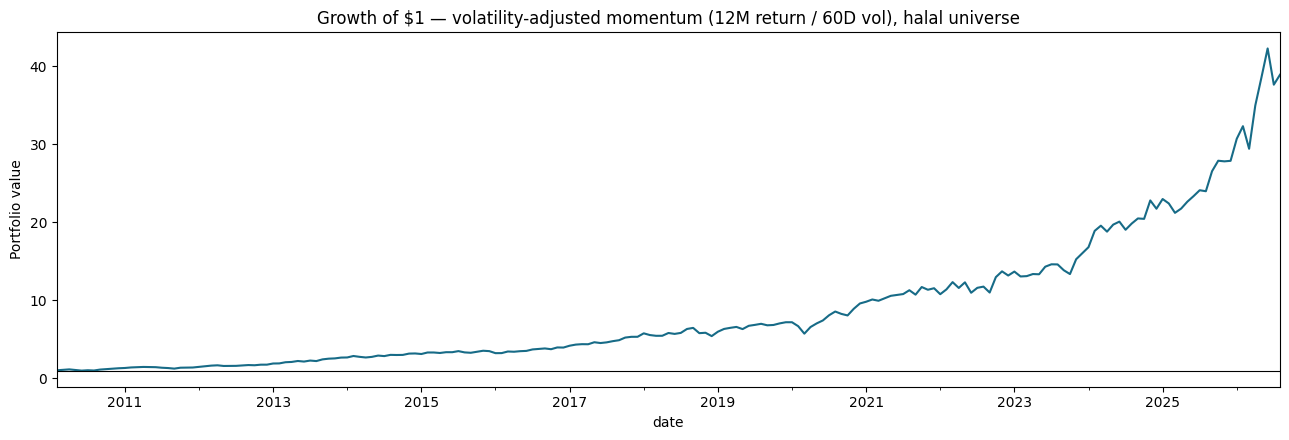

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.5))
wealth.plot(ax=ax, color='#176b87', title='Growth of $1 — volatility-adjusted momentum (12M return / 60D vol), halal universe')
ax.set_ylabel('Portfolio value')
ax.axhline(1, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

## Monthly performance

Monthly returns of the volatility-adjusted momentum strategy.

In [9]:
table = (portfolio_returns * 100).rename('ret').to_frame()
table['year'] = table.index.year
table['month'] = table.index.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_table = table.pivot(index='year', columns='month', values='ret').reindex(columns=month_order)

annual_return = portfolio_returns.groupby(portfolio_returns.index.year).apply(lambda x: (1 + x).prod() - 1) * 100
monthly_table['Year'] = annual_return

monthly_summary = pd.Series({
    'months': len(portfolio_returns),
    'positive_months': int((portfolio_returns > 0).sum()),
    'pct_positive_months': float((portfolio_returns > 0).mean()),
    'avg_monthly_return': float(portfolio_returns.mean()),
    'median_monthly_return': float(portfolio_returns.median()),
    'best_month': portfolio_returns.idxmax().strftime('%Y-%m'),
    'best_month_return': float(portfolio_returns.max()),
    'worst_month': portfolio_returns.idxmin().strftime('%Y-%m'),
    'worst_month_return': float(portfolio_returns.min()),
})

styled = (
    monthly_table.round(1)
    .style.format(precision=1, na_rep='')
    .background_gradient(cmap='RdYlGn', axis=None, vmin=-15, vmax=15, subset=month_order)
    .set_caption('Monthly return (%) by year')
)
display(styled)
display(monthly_summary.to_frame('value'))

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year
year,,,,,,,,,,,,,
2010,,3.6,6.3,4.7,-7.3,-6.9,4.8,-3.2,11.8,5.0,4.5,4.8,29.8
2011,2.6,5.2,2.6,1.9,-1.0,-1.1,-5.0,-3.0,-5.5,9.3,0.5,1.4,7.4
2012,5.9,5.9,4.6,2.4,-5.1,0.5,0.4,3.4,3.0,-1.5,4.4,0.1,26.1
2013,8.4,0.7,7.8,1.8,5.7,-3.3,5.9,-2.8,9.8,3.7,1.4,4.1,51.5
2014,0.6,7.0,-3.8,-3.0,3.0,6.0,-2.3,5.5,-0.6,0.4,5.5,0.6,19.8
2015,-2.2,6.2,0.0,-1.9,3.1,-0.1,4.2,-4.7,-1.5,4.1,3.6,-1.4,9.3
2016,-7.5,0.2,6.3,-0.9,2.1,1.0,5.4,1.7,1.7,-2.5,6.0,-0.3,13.1
2017,6.0,3.4,1.2,-0.2,5.9,-2.2,1.9,3.4,2.5,6.9,1.8,0.1,34.9
2018,8.3,-3.8,-1.7,0.1,6.5,-2.0,2.2,8.6,2.2,-10.4,0.9,-7.3,1.6


,value
months,199
positive_months,136
pct_positive_months,0.683417
avg_monthly_return,0.019901
median_monthly_return,0.021327
best_month,2026-04
best_month_return,0.188639
worst_month,2020-03
worst_month_return,-0.143358


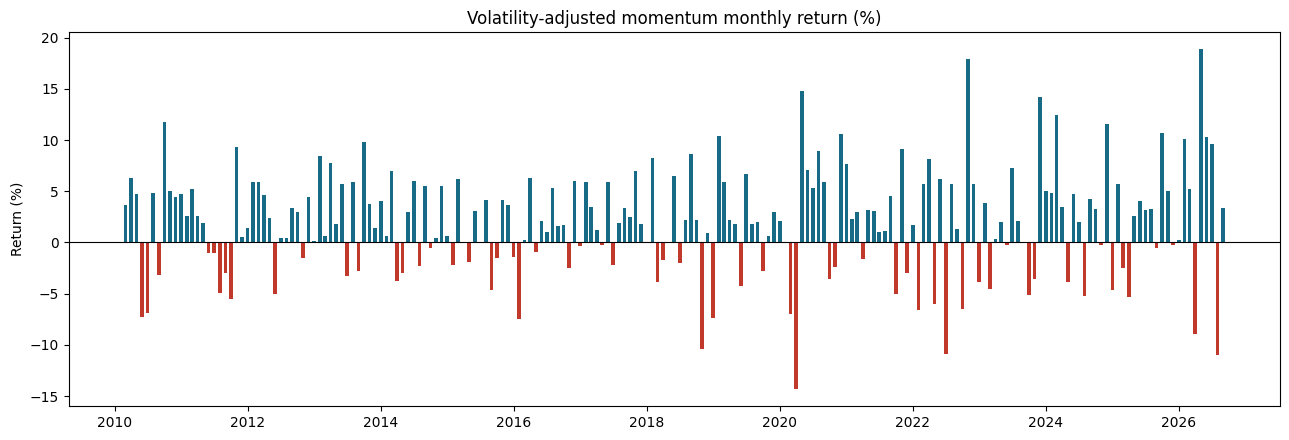

In [10]:
colors = np.where(portfolio_returns >= 0, '#176b87', '#c0392b')
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(portfolio_returns.index, portfolio_returns.values * 100, width=20, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Volatility-adjusted momentum monthly return (%)')
ax.set_ylabel('Return (%)')
plt.tight_layout()
plt.show()

## Caveats and next improvements

- **Look-ahead / survivorship bias in the universe**: `equities-list.csv` is today's list of halal
  candidates, projected backward. Stocks added or delisted over time aren't reconstructed
  point-in-time.
- **Price-only bars**: like the other notebooks, this uses IBKR `TRADES` bars — split-adjusted but
  not dividend-adjusted.
- **No transaction costs**: commissions, spread, and market impact from monthly rebalancing are
  excluded.
- **No skip month**: this specification ranks on the full trailing 12-month return, unlike the
  12-1 momentum notebooks which deliberately skip the most recent month to avoid short-term
  reversal. Volatility-scaling and skip-month are separate ideas — nothing stops combining them,
  but this notebook implements the score exactly as specified.
- **Volatility as a denominator is unstable near zero**: a stock with an unusually quiet 60-day
  window gets a very large score from a small denominator, even if its 12-month return is modest.
  The score is a ratio, not a bounded z-score, so an extreme volatility outlier can dominate the
  ranking; a production version might winsorize volatility or blend this with a raw-momentum
  signal.
- **Ranking universe drift**: many tickers (recent IPOs, in particular) don't have 13 months of
  history in earlier years and simply aren't eligible until they do; `MIN_UNIVERSE` guards against
  ranking with too few names but doesn't correct for the universe being thin in its earliest years.
- A serious version of this strategy would need a point-in-time halal screen, total-return prices,
  realistic transaction costs, and probably a side-by-side comparison against the raw 12-1 momentum
  notebook to isolate exactly what volatility-scaling changes about the resulting portfolio.